# Handwriting and Digitization

Graduate Quantitative Economics and Datascience

Jesse Perla (University of British Columbia)

# From Images to Data

## Three Ways to Read Handwriting

| Approach | Output | Main tradeoff |
|:-----------------------|:-----------------------|:-----------------------|
| **OCR specialist:** Chandra | Document → HTML table | Native table output; limited instruction following |
| **General vision-language model:** Qwen or Claude | Image → requested JSON | Flexible; check guesses and omissions |
| **Corpus fine-tune:** adapted Chandra | Archive’s HTML / JSON | Learns local conventions; needs labeled pages |

- These models process **images and text together**
- **Local versus hosted** is a separate choice: MLX/Ollama use our hardware; Claude sends images to a paid service
- Background: Melissa Dell’s [OCR and Record Linkage](https://econdl.github.io/intro/2023/03/24/lecture16.html) ([lecture notes](https://www.dropbox.com/scl/fi/4uupqzcc5cymufy6f1jsz/lecture_OCR_linkage.pdf?rlkey=9faznu1hxsy86bml367pow15w&dl=0)) and [survey, §8.5](https://arxiv.org/html/2407.15339v3#S8.SS5)

## Reading the Letters Is Only Part of the Task

- **Full page:** the model must locate the table, identify columns, and associate each value with a person
- **Prepared panels or row crops:** we supply some of that structure. Recognition becomes easier, but somebody must prepare the inputs
- **HTML or JSON → DataFrame:** a parseable table can still have shifted columns, omitted people, or invented values
- Compare **reading accuracy and extraction coverage**. A model that reads the surviving cells well may still lose much of the table
- Toronto uses prepared ten-row panels; Paris compares pages with row crops; Argentina exposes a full-page layout failure

## What Does Fine-Tuning Change?

- **Prompting:** choose instructions and perhaps show examples; the model’s weights stay fixed
- **Fine-tuning:** start with a pretrained model and update parameters using images paired with correct output text
- **LoRA (low-rank adaptation):** freeze the original weights and learn small update matrices. Save these as an **adapter** that needs the matching base model
- **Quantization:** store weights with fewer bits to reduce memory. Downloading, quantizing, or merging an existing adapter does not train a model
- Here we run published models and adapters. **We do no training.** See the [PEFT LoRA guide](https://huggingface.co/docs/peft/en/developer_guides/lora) and the optional section at the end

## Training, Development, and Test Mean Different Things

| Split | What its labels are used for |
|:-----------------------------------|:-----------------------------------|
| **Training** | Update weights or LoRA parameters |
| **Development / validation** | Choose prompts, image size, training settings, and parsing/scoring rules |
| **Test** | Measure the frozen workflow on new documents |

- Split writers/documents **before making crops**: rows on one page share handwriting and context
- Even without training, choose prompts on development pages and evaluate on test pages
- Changes after seeing test failures make revised scores **exploratory**; a final estimate needs untouched pages
- Held out from fine-tuning does not mean absent from base-model **pretraining**

## What Evidence Will These Examples Provide?

| Example | Development or training | Evaluation shown here |
|:-----------------------|:-----------------------|:-----------------------|
| Toronto | 1 development page; no training by us | 8 other writers, 103 labeled people |
| Paris | 2 development pages; no training by us | 4 other writers, 120 annotation rows |
| Argentina: seen page | Page used to train the published adapter | 15 people; **training-page demonstration** |
| Argentina: held-out page | Author’s blur-model test split | 15 people; **author-selected best page, blurred input** |
| Thai bill | Image from the published dataset’s train split | One crop; **no held-out accuracy claim** |

- Toronto and Paris also include **retrospective scoring or alignment changes**, identified alongside their results
- These are different tasks and levels of assistance. Their percentages do not form one overall model ranking

# Toronto, 1901

## Vibe-coding Warning!

This material has not yet been fully vetted and checked.

## Turning a Census into Economic Data

In [2]:
import json
from pathlib import Path
import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, display, Markdown, HTML

ocr_dir = Path("data/handwriting")
toronto_dir = ocr_dir / "toronto"
toronto_sample = json.loads(
    (toronto_dir / "scores/test_sample.json").read_text())

<figure>
<img src="https://central.bac-lac.gc.ca/.item/?id=z000106253&amp;app=census1901&amp;op=img.png" alt="Toronto census, 1901: fifty handwritten people." />
<figcaption aria-hidden="true">Toronto census, 1901: fifty handwritten people.</figcaption>
</figure>

- **Who worked, in what occupation, and for how much?** Canada’s 1901 census records names, ages, occupations, and earnings
- OCR turns pixels into text. A document model can also return a table we can load into **pandas**
- Compare **Chandra OCR 2**, **Qwen3.8 27B**, and **Qwen3.5 2B**, running locally with the tools from the [open-weight LLM lecture](local_llms.qmd)
- Scan: [Library and Archives Canada, RG31-C-1](https://recherche-collection-search.bac-lac.gc.ca/eng/Home/Record?app=census&IdNumber=36505776&ecopy=z000106253&ST=SCTA), enumerator James F. Hutchman

## Research Labels Already Exist

- [York’s Toronto Area Test Sample](https://www.yorku.ca/ccri/) contains **52,702 people** from a 20% sample of dwellings. These are human-entered research records
- We match scans using district, subdistrict, poll, page, enumerator, and physical line number; the published page identifiers need inspection
- York’s name **“Test Sample”** describes its research dataset. It is not a predefined OCR train/test split

## Toronto: Our Split, with No Model Training

| Role        | Pages / writers | Labeled people | Used for                  |
|:------------|----------------:|---------------:|:--------------------------|
| Development |           1 / 1 |             26 | Design panels and prompts |
| Test        |           8 / 8 |            103 | Compare with York records |

- Page IDs were fixed **before inference**, using scan availability and verified alignment; this is not a random sample
- Transcribe **400 visible rows**; score 103 York records. The other 297 people have no labels
- Writers do not overlap. **No weights are fitted; no reference answers enter the prompts**
- Column recovery and digit scoring were revised **after viewing outputs**: exploratory scores on saved runs

## Give Each Model the Same Image

<figure>
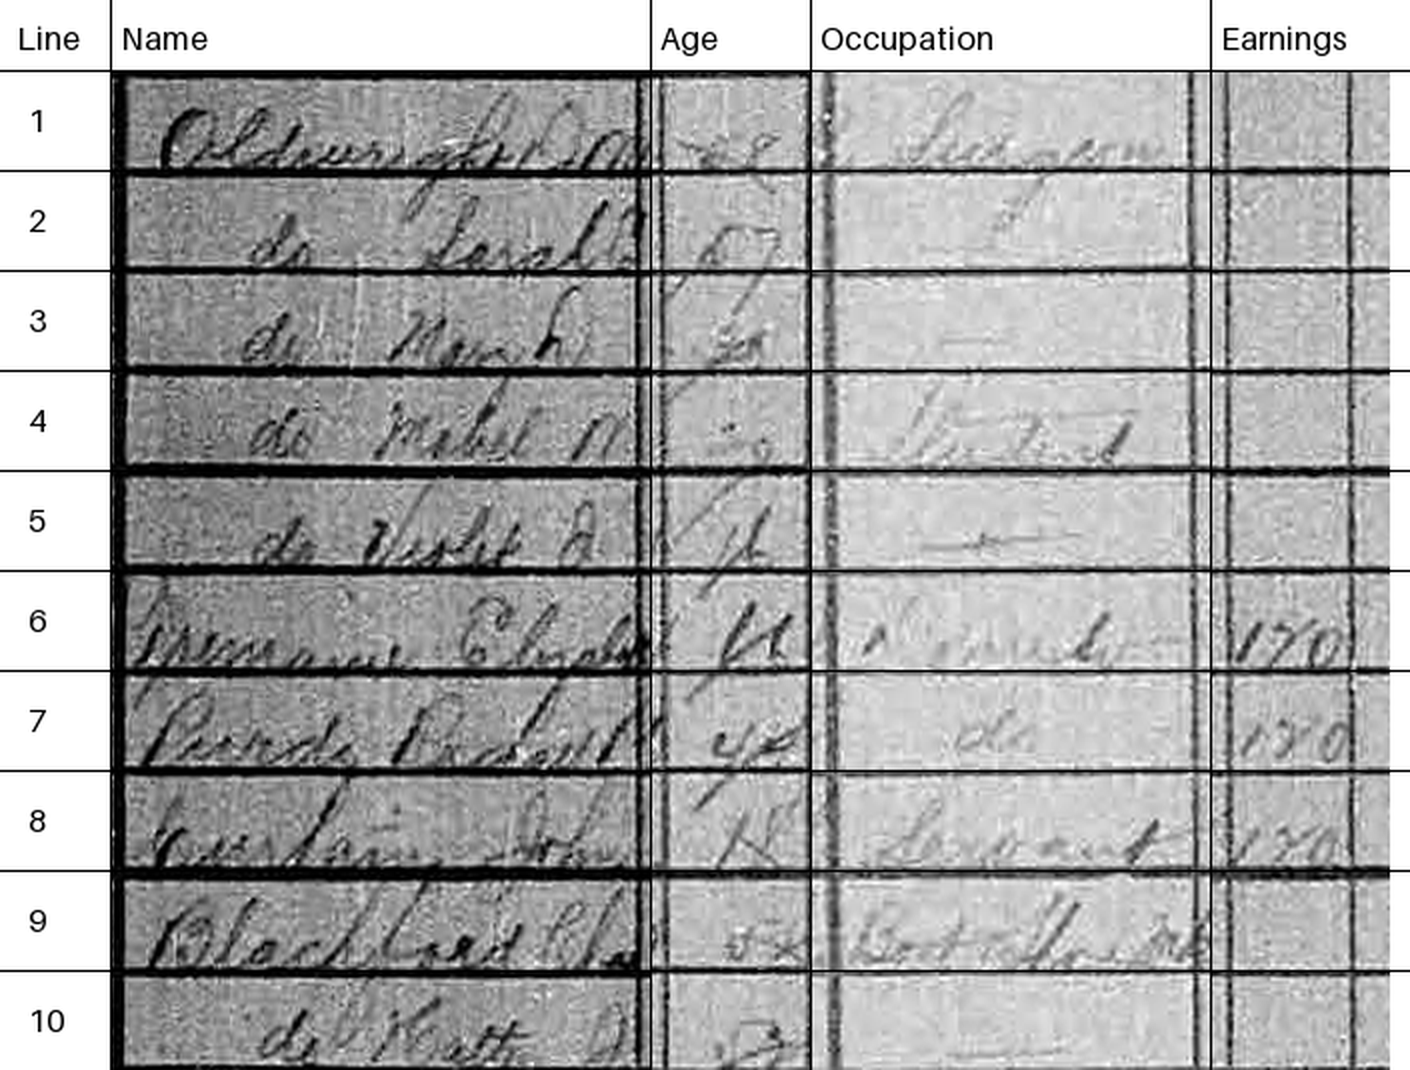
<figcaption aria-hidden="true">The actual ten-row input shared by all three models.</figcaption>
</figure>

- Manually locate the page, columns, and row boundaries; rectify the scan and assemble **ten-row panels**
- Add modern headings and physical line numbers. Every model receives the **same 1410 × 1070 PNG**
- This measures **assisted transcription**. Automatic page layout recovery is a separate task
- [LAC source scan](https://central.bac-lac.gc.ca/.item/?id=z000106253&app=census1901&op=img), lines 1–10. Geometry and download code are included

## Three Local Workflows

| Workflow      | Local runtime     | Output                     |
|:--------------|:------------------|:---------------------------|
| Chandra OCR 2 | MLX, BF16 weights | Native OCR prompt → HTML   |
| Qwen3.8 27B   | Ollama MLX, MXFP8 | Fixed schema prompt → JSON |
| Qwen3.5 2B    | Ollama, GGUF Q8_0 | The same JSON prompt       |

- Temperature 0, at most 4,096 output tokens per panel; Qwen thinking disabled
- Chandra is an OCR specialist. Qwen is a general vision-language model; use each model’s supported interface
- We compare complete workflows, including quantization and prompts. These results do not isolate model weights
- All three were run on an Apple M4 Max with 64 GB. **No fine-tuning** is performed

## Download Chandra from Hugging Face

From the repository root, install the optional packages on an Apple Silicon Mac:

``` bash
uv sync --extra handwriting --extra handwriting-mac
```

Then run this Python code once:

``` python
from huggingface_hub import snapshot_download

model_path = snapshot_download(
    repo_id="datalab-to/chandra-ocr-2",
    revision="af93b47dba1b47b6640c86ccf487ed2260ab9a09",
    local_dir="build/handwriting/model",
)
```

- Downloads weights, tokenizer, and processor at the pinned revision; existing files are reused
- About **10 GB for the weights**, plus inference memory. [Hub download docs](https://huggingface.co/docs/huggingface_hub/guides/download); [NVIDIA/vLLM alternative](https://github.com/datalab-to/chandra#usage)

## Chandra: an Image Path to HTML

``` python
from chandra.prompts import OCR_PROMPT
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.utils import load_config

model_path = "build/handwriting/model"
image_path = "slides/data/handwriting/toronto/input_illustration.png"
model, processor = load(model_path)
prompt = apply_chat_template(
    processor, load_config(model_path), OCR_PROMPT, num_images=1,
)
result = generate(
    model, processor, prompt, image=[image_path],
    max_tokens=4096, temperature=0.0, verbose=False,
)
html = result.text
print(html)
```

- MLX loads the model **inside Python**; this call needs no server. Reuse `model` and `processor` for further images
- [`handwriting_mlx.py`](../code/handwriting_mlx.py) takes any local image path. The saved benchmarks use MLX’s server interface; the [MLX Python interface](https://github.com/Blaizzy/mlx-vlm#python-script) exposes the same model

## Download Qwen and Describe the Output

With Ollama installed and running, choose a model:

``` bash
ollama pull qwen3.5:2b
ollama pull qwen3.8:27b-mxfp8
```

Use the same instruction for both vision-language models:

``` python
prompt = (
    'Extract every row of this census table as JSON. Return only an object '
    'with key "rows", a list of objects with string fields "line", "name", '
    '"age", "occupation", "earnings". Read only the image. Preserve spelling '
    'and abbreviations, including ditto marks. Do not fill blanks or infer '
    'missing values. Use an empty string for an empty cell. Keep every row in '
    'printed order. No commentary.'
)
```

- The **2B model needs less memory**; the 27B MXFP8 run here uses Ollama’s Apple Silicon MLX runtime. These are image-capable chat models, not `qwen3-embedding`

## Qwen: the Same Image Path to JSON

``` python
import base64, json
from pathlib import Path
from urllib.request import Request, urlopen

image_path = Path("slides/data/handwriting/toronto/input_illustration.png")
encoded = base64.b64encode(image_path.read_bytes()).decode()
payload = {
    "model": "qwen3.5:2b", "stream": False, "think": False,
    "messages": [{"role": "user", "content": prompt, "images": [encoded]}],
    "options": {"temperature": 0, "num_predict": 4096, "num_ctx": 16384},
    "keep_alive": "10m",
}
request = Request("http://127.0.0.1:11434/api/chat",
    data=json.dumps(payload).encode(),
    headers={"Content-Type": "application/json"})
with urlopen(request, timeout=600) as response:
    reply = json.load(response)
print(reply["message"]["content"])
```

- `prompt` is the preceding slide’s instruction. Change `model` to `qwen3.8:27b-mxfp8` for the larger model
- [Ollama’s image API](https://docs.ollama.com/capabilities/vision) takes base64 bytes. Responses can contain Markdown fences or stop early; the [batch reader](../code/toronto_census_ocr.py) handles these before scoring

## Run One Image, Then the Full Example

From the repository root, using the included Toronto panel:

``` bash
uv run --extra handwriting --extra handwriting-mac \
  python code/handwriting_mlx.py \
  slides/data/handwriting/toronto/input_illustration.png
uv run python code/handwriting_qwen.py \
  slides/data/handwriting/toronto/input_illustration.png
```

- These small scripts print the **raw model response**. Replace the final path with your own image; Qwen accepts `--model qwen3.8:27b-mxfp8`
- For the complete sample, [`build_toronto_census.py`](../utilities/build_toronto_census.py) downloads and prepares the panels; [`toronto_census_ocr.py`](../code/toronto_census_ocr.py) runs them and saves responses, CSVs, and metadata. [Full commands](data/README.md)
- In lecture notebooks, images are under `data/handwriting/`. **Model calls are displayed, not executed when rendering**

## From Model Output to a DataFrame

In [3]:
toronto_people = pd.read_csv(
    toronto_dir / "qwen27b/test_predictions.csv",
    dtype=str, keep_default_na=False, na_values=["NaN"],
)

In [4]:
display(HTML(toronto_people.loc[
    toronto_people.page_id.eq("z000106253"),
    ["line", "name", "age", "occupation", "earnings"]
].head(3).to_html(index=False)))

- These are **Qwen 27B predictions** for the illustrated panel, including any mistakes. JSON and Chandra’s HTML cells become the same columns
- `""` means an extracted blank; `NaN` means unavailable output. Neither means zero earnings
- `page_id` and `line` join predictions to references. Names and occupations remain raw, unscored strings

## Score Individual Digits

- Score **age and earnings** after currency normalization, whole-dollar rounding, and converting infant ages to completed years

$$
\text{Digit accuracy}
= 1 - \frac{\text{substitutions + deletions + insertions}}
              {\text{reference digits}}
$$

- Align characters **within each person’s value** using minimum edit distance. `53 → 23` has one error among two digits: **50%**; `350 → 35` gives **66.7%**
- Sum edits and reference digits over **available filled cells**. An extracted blank loses every reference digit; `NaN` is excluded and reported in **coverage**
- Extra digits or unrecognized characters count as edits. Blank reference cells and exact whole-value agreement are reported separately

## Digit Accuracy on the 103 Test People

In [5]:
toronto_scores = pd.read_csv(toronto_dir / "scores/test_field_scores.csv")
toronto_models = {"chandra": "Chandra OCR 2",
                  "qwen27b": "Qwen 27B", "qwen2b": "Qwen 2B"}
toronto_table = pd.DataFrame(index=["age", "earnings"])
for model, name in toronto_models.items():
    score = toronto_scores.loc[toronto_scores.workflow.eq(model)]
    score = score.set_index("field")
    toronto_table[name] = [
        f"{r.digit_accuracy:.1%}" for r in score.loc[
            toronto_table.index].itertuples()]
display(HTML(toronto_table.to_html()))

- Age: **186 reference digits**, covering all 103 labeled people for each model
- Earnings: Chandra covers **27/29** filled cells (80 digits); each Qwen covers **29/29** (86 digits). Accuracy is conditional on these available values
- These scores compare normalized research labels, using the split and retrospective scoring rules described earlier
- Errors can cluster by writer and page. Eight writers do not establish a general model ranking

## Report Coverage Alongside Accuracy

In [6]:
toronto_structure = pd.read_csv(toronto_dir / "scores/test_structure.csv")
diagnostics = pd.DataFrame(index=list(toronto_models.values()))
diagnostics["Age cells available"] = [
    f"{r.age_available}/{r.expected_cells_per_field}"
    for r in toronto_structure.itertuples()]
diagnostics["Earnings cells available"] = [
    f"{r.earnings_available}/{r.expected_cells_per_field}"
    for r in toronto_structure.itertuples()]
earnings_rows = toronto_scores.loc[toronto_scores.field.eq("earnings")]
diagnostics["Blank earnings: matches / available"] = [
    f"{r.blank_correct}/{r.blank_available}"
    for r in earnings_rows.itertuples()]
display(HTML(diagnostics.to_html()))

- Keep uniquely numbered rows and unambiguous columns; unavailable values become **`NaN`**, without rejecting the rest of the table
- Coverage includes **all 400 visible rows**. Four Chandra earnings columns are unavailable; their ages remain usable
- Of 74 labeled blank earnings cells, Chandra has **68 available**; six are `NaN`. Qwen 27B’s eight unavailable rows have no York labels
- The [label audit](data/handwriting/toronto/audit.json) flags three ages on two pages (Maclennan and Murray). We retain the published labels; agreement is not unquestionable ground truth

## An Ambiguous Earnings Column Becomes NaN

Chandra creates a two-column earnings header on the Forbes page:

``` html
<th colspan="2">Earnings</th>
```

Its row 6 contains two earnings cells:

``` html
<td>$120</td><td>-</td>
```

- There are still ten rows, but **six cells per row** instead of the five expected fields
- The header assigns **two positions to Earnings**, so that column is ambiguous. Three Forbes panels and one Moore panel have this layout
- The parser stores **`NaN` for earnings** and retains name, age, and occupation. It does not guess which earnings subcolumn to use
- For example, Forbes line 17 becomes `age="71", earnings=NaN`. The age is scored independently

## Why Is Age Agreement Low?

In [7]:
age_audit = json.loads((toronto_dir / "scores/test_age_audit.json").read_text())
age_breakdown = pd.Series(age_audit["disagreements"], name="Disagreements")
display(HTML(age_breakdown.to_frame().to_html()))

- **35 whole-age disagreements = 103 people − 68 matches.** These involve **42 digit edits among 186 digits**, giving **77.4% digit accuracy**
- **21 come from the Hutchman page alone.** On one panel, Chandra invents the age sequence **74, 75, …, 83**. Faint handwriting and our image preparation need separate investigation
- Three reference ages are flagged, not corrected. The other eleven disagreements include digit confusions such as **53 → 23**
- Eight correct ages survive the unavailable earnings columns. All 103 labeled ages are included; the difficult page remains in the benchmark

## How Errors Affect an Earnings Calculation

In [8]:
toronto_earnings = pd.read_csv(toronto_dir / "scores/test_earnings.csv")
earnings_table = pd.DataFrame({
    "Model": toronto_earnings.workflow.map(toronto_models),
    "Numeric / labeled": [
        f"{r.numeric_predictions}/{r.reference_annual_earners}"
        for r in toronto_earnings.itertuples()],
    "Paired reference mean":
        toronto_earnings.paired_reference_mean,
    "OCR mean": toronto_earnings.predicted_mean,
    "Mean abs. error": toronto_earnings.paired_mean_absolute_error,
})
display(HTML(earnings_table.to_html(index=False, float_format="${:,.0f}".format)))

- Select people with positive **annual earnings in the reference**; exclude explicitly daily, weekly, or monthly amounts
- Each model’s means and error use its own available numeric predictions. **Coverage differs**, so these errors are conditional on different subsets
- Missing predictions are never zeros. Formatting such as `120 00` is nonnumeric under the frozen rules
- Qwen 27B’s mean is **\$365 versus \$361**, yet its mean absolute error is **\$63**. Errors can cancel; these sample means are not estimates for Toronto

# Paris Census Tables

## Vibe-coding Warning!

This material has not yet been fully vetted and checked.

## An Archive with Literal Transcriptions

In [9]:
ocr_pages = pd.read_csv(ocr_dir / "pages.csv")
ocr_labels = pd.read_csv(ocr_dir / "labels.csv", dtype=str,
                         keep_default_na=False)
demo_page = "AD075DP_D2M8_275_0025_left_page"

<figure>
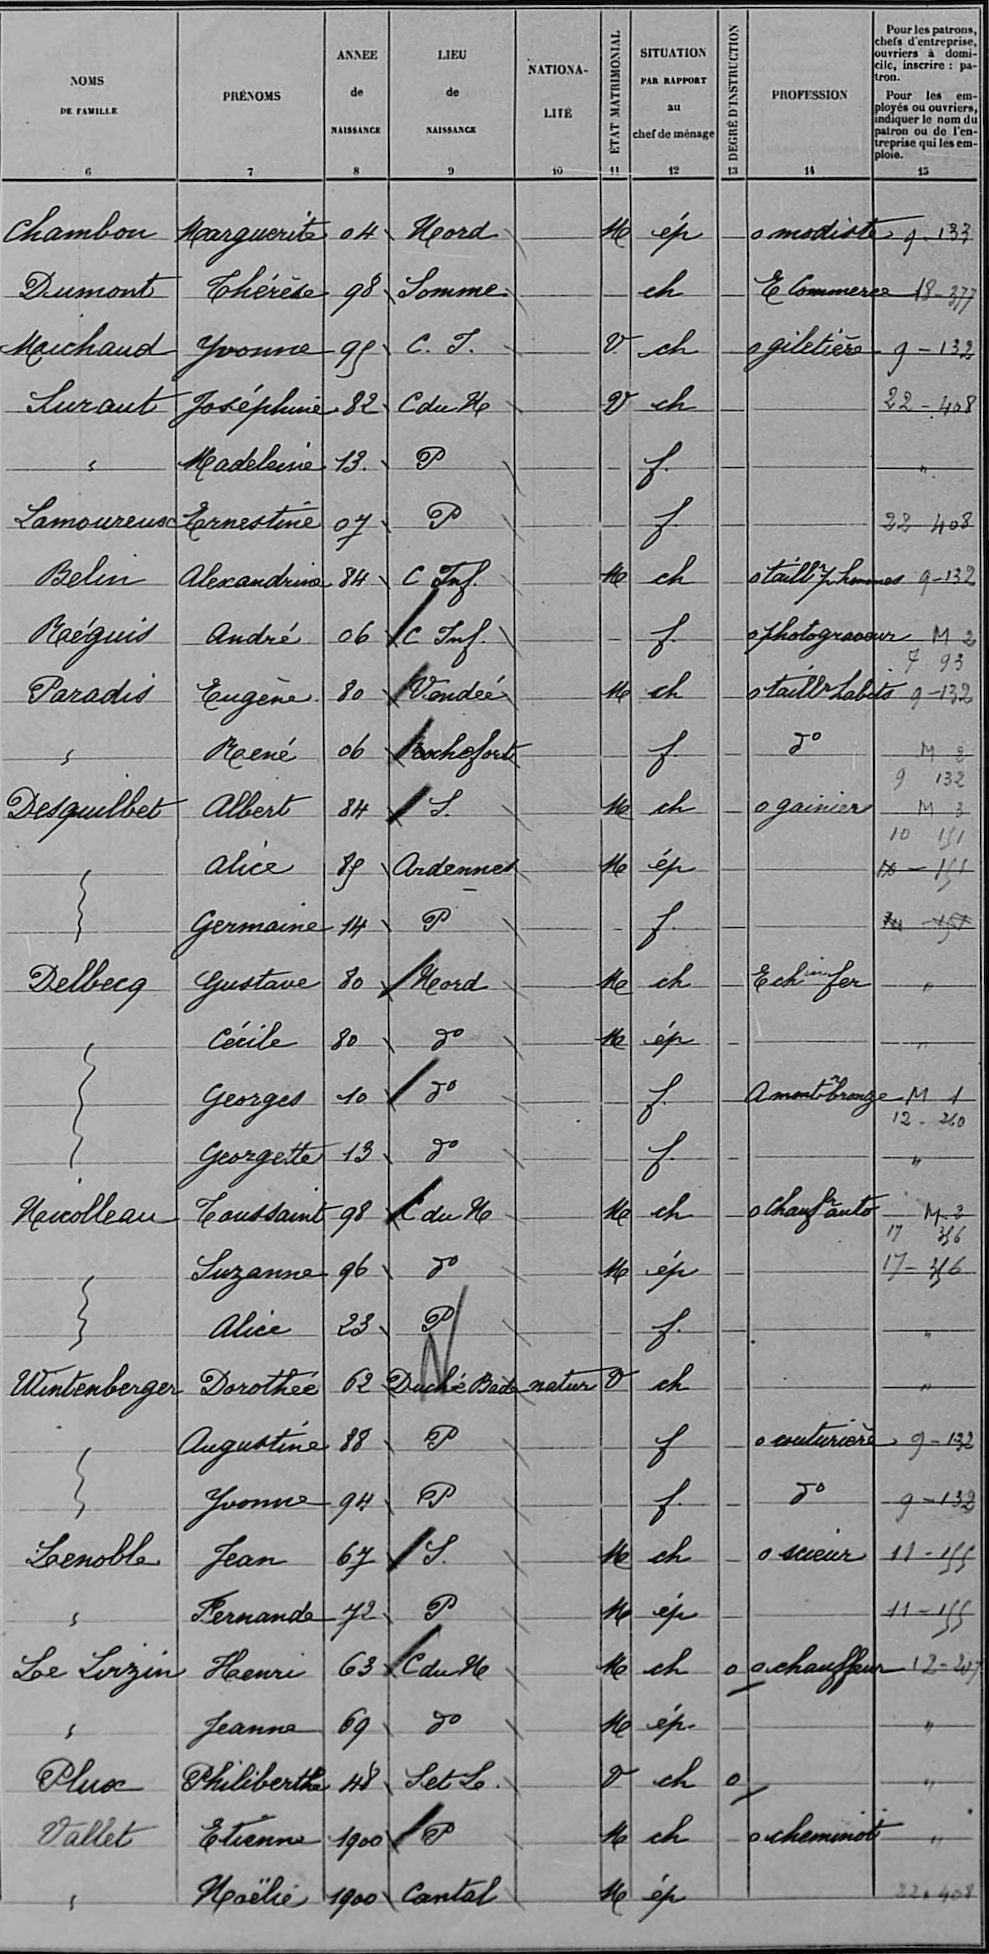
<figcaption aria-hidden="true">Paris census, 1926: handwritten people and occupations.</figcaption>
</figure>

- **Who lived and worked in Paris in 1926?** These French tables record birthplaces, occupations, and household relationships
- The [POPP census dataset](https://doi.org/10.5281/zenodo.6581158) has independently published literal transcriptions (Constum et al., 2022; CC BY 4.0). Images and labels ship with the notebook
- Compare recovery of a **complete page** with recognition of one cropped row at a time; layout and handwriting are separate sources of error
- The next lecture develops [vision-language models](image_classification.qmd) further

## A Person, a Row, Ten Fields

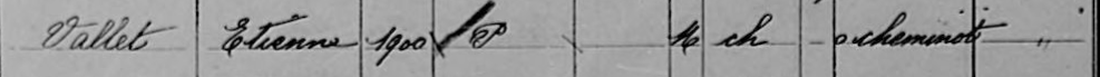

In [10]:
demo_row = ocr_labels.loc[
    ocr_labels.row_id.eq(f"{demo_page}_28")].iloc[0]
demo_image = PILImage.open(ocr_dir / "pages" / f"{demo_page}.png")
x, y, w, h = (int(demo_row[k]) for k in ["x", "y", "width", "height"])
display(demo_image.crop((x, y, x + w, y + h)).resize(
    (1100, round(h * 1100 / w)), PILImage.Resampling.LANCZOS))
display(HTML(demo_row[["surname", "given_names", "birth_year",
                       "occupation"]].to_frame().T.to_html(index=False)))

- The row says **Vallet, Etienne, 1900**, with occupation **o cheminot** (railway worker). These are reference labels, before any model call
- Other columns record birthplace, nationality, marital status, relationship, education, and employer/statistical code
- Preserve the original strings: `07` is a birth year as written, not an age. Expanding dates, occupation codes, and ditto marks is a separate research decision

## Paris: Preserve the Source’s Writer Split

| Source split | Used in this lecture | Purpose |
|:-----------------------|:-----------------------|:-----------------------|
| Training | No pages used for fitting | Available for a future fine-tune |
| Validation | 2 pages / 2 writers / 60 people | Choose prompt and image size |
| Test | 4 pages / 4 other writers / 120 rows | Compare saved predictions |

- Four of eight source test double pages, left pages only; IDs fixed **before inference**
- **120 annotations = 119 people + 1 employer-code-only region**, with ten fields each
- Scoring and alignment were revised **after viewing outputs**; automatic and assisted results stay separate
- Public since 2022; base-model pretraining exposure is unknown. [Provenance](data/README.md)

## Paris: Prepare a Page for Chandra

Start the local server with the Chandra OCR 2 weights downloaded earlier:

``` bash
uv run --extra handwriting-mac python -m mlx_vlm.server \
  --model build/handwriting/model --host 127.0.0.1 --port 8081
```

In a separate Python session, from the repository root:

``` python
import base64
from io import BytesIO
from pathlib import Path
from PIL import Image

image_path = (Path("slides/data/handwriting/pages")
              / "AD075DP_D2M8_275_0025_left_page.png")
image = Image.open(image_path)
image = image.resize((image.width * 2, image.height * 2),
                     Image.Resampling.LANCZOS)
buffer = BytesIO()
image.convert("RGB").save(buffer, format="PNG")
encoded = base64.b64encode(buffer.getvalue()).decode()
```

- The script doubles the page dimensions, then encodes its pixels for the request. The **row runs** instead crop an annotation box and resize it to 128 pixels high

## Paris: Call Chandra from Python

``` python
from chandra.prompts import OCR_PROMPT
from openai import OpenAI

client = OpenAI(base_url="http://127.0.0.1:8081/v1",
                api_key="local", timeout=300)
response = client.chat.completions.create(
    model="build/handwriting/model",
    messages=[{"role": "user", "content": [
        {"type": "image_url", "image_url": {
            "url": f"data:image/png;base64,{encoded}"}},
        {"type": "text", "text": OCR_PROMPT},
    ]}],
    temperature=0, max_tokens=8192,
)
html = response.choices[0].message.content
print(html)
```

- `encoded` is the preceding slide’s image. `OCR_PROMPT` requests Chandra’s **HTML transcription**; no reference answers enter the request
- The `OpenAI` client talks to **our local MLX server** with a placeholder key. Code: [single-page script](../code/handwriting_ocr.py), [batch script](../utilities/build_handwriting_predictions.py)

## From HTML to pandas

``` python
from io import StringIO

people = pd.read_html(StringIO(html), keep_default_na=False)[0]
```

In [11]:
ocr_cells = pd.read_csv(ocr_dir / "scores/cells.csv",
                        keep_default_na=False, na_values=["NaN"])
ocr_frame = pd.read_csv(ocr_dir / "chandra/demo.csv", dtype=str,
                        keep_default_na=False)
display(HTML(ocr_frame[["surname", "given_names", "birth_year",
                        "occupation"]].head(3).to_html(index=False)))

- This is the table from the saved Chandra response. The [full reader](../code/handwriting_ocr.py) preserves strings and names the columns; parsing does not verify handwriting

## Calling Hosted Claude from Python

With Claude Code installed and signed in, from the repository root:

``` python
import json, shutil, subprocess, tempfile
from pathlib import Path

data = Path("slides/data/handwriting")
image_path = data / "pages/AD075DP_D2M8_275_0025_left_page.png"
instruction = (data / "claude_prompt.txt").read_text()
with tempfile.TemporaryDirectory() as folder:
    shutil.copyfile(image_path, Path(folder) / "census.png")
    result = subprocess.run(
        ["claude", "-p", "--model", "opus", "--output-format", "json",
         "--tools", "Read", "--allowedTools", "Read"],
        input=instruction + "census.png", cwd=folder,
        text=True, capture_output=True, check=True,
    )
print(json.loads(result.stdout)["result"])
```

- This uploads the image for **hosted inference**; no Claude weights download. The temporary folder contains only the scan
- [`claude_prompt.txt`](data/handwriting/claude_prompt.txt) requests ten transcription fields, without reference answers. [Batch script](../utilities/build_handwriting_claude.py); [CLI docs](https://code.claude.com/docs/en/headless). The saved run resolved `opus` to **Opus 5.5**

## What Counts as Correct?

- Align rows and fields first; score each cell independently. An ambiguous merged cell becomes **`NaN`**, preserving the other columns. An extracted blank remains a prediction
- **Character accuracy = 1 − character edits / reference characters**, summed within available filled cells. Numeric birth years use the same calculation digit by digit; keep stray predicted characters as errors
- Keep case, accents, punctuation, and ditto marks. Only annotation markers, Unicode, and whitespace are normalized. Insertions can make accuracy negative
- Report **coverage beside accuracy**. Exact recovery over **all** reference cells also counts extraction failures: unavailable cells contribute zero correct cells
- Source-checked alignment repairs are labeled **assisted**; the automatic extraction results remain separate

## Reading the 120 Annotation Rows

In [12]:
ocr_scores = pd.read_csv(ocr_dir / "scores/field_scores.csv")
claude_scores = pd.read_csv(ocr_dir / "claude_scores/field_scores.csv")
fields_shown = ["surname", "given_names", "birth_year", "occupation"]
accuracy_table = pd.DataFrame({
    "Field": ["Surname", "Given names", "Birth year (digits)", "Occupation"],
})
for label, scores in [("Chandra OCR 2 (page)", ocr_scores),
                       ("Claude Opus 5.5", claude_scores)]:
    scores = scores.set_index("field")
    accuracy_table[label] = [scores.loc[f, "digit_accuracy"
        if f == "birth_year" else "character_accuracy"] for f in fields_shown]
display(HTML(accuracy_table.to_html(formatters={
    "Chandra OCR 2 (page)": "{:.1%}".format,
    "Claude Opus 5.5": "{:.1%}".format,
}, index=False)))
ocr_summary = pd.read_csv(ocr_dir / "scores/summary.csv").iloc[0]
claude_summary = pd.read_csv(ocr_dir / "claude_scores/summary.csv").iloc[0]
display(Markdown(
    f"Separate run, Chandra row crops: **{ocr_summary.cer:.1%} CER**, "
    f"**{ocr_summary.wer:.1%} WER**; "
    f"{int(ocr_summary.exact_lines)}/120 exact lines."
))

- **Source-audited alignment:** all filled cells in these four fields are available. Across all ten fields, available cells cover **99.9% of reference characters**; this is coverage, not correctness
- Both models saw the same images and **no labels**. Claude used a column-specific JSON prompt; this compares workflows. Exact-cell scores and every denominator are saved

## Layout Recovery Remains Visible

In [13]:
structure = pd.read_csv(ocr_dir / "scores/structure.csv")
claude_structure = pd.read_csv(ocr_dir / "claude_scores/structure.csv")
structure_table = pd.DataFrame([
    {"Model": name,
     "Automatic cells": f"{s.automatic_cells:.0f}/1200",
     "After source audit": f"{s.available_cells:.0f}/1200",
     "Automatic exact recovery": f"{s.automatic_exact_yield:.1%}"}
    for name, s in [("Chandra OCR 2", ocr_summary),
                    ("Claude Opus 5.5", claude_summary)]
])
display(HTML(structure_table.to_html(index=False)))

- Both emit **30, 30, 30, 29 rows**: 3/4 annotation counts match. This is a count check, not proof of correct layout
- On the final page, a source-image audit finds **29 people plus an employer-code-only annotation**, possibly overlapping the last person. Align those 29 rows; retain the extra reference region as `NaN`
- Chandra returns **two braces spanning five blank surname cells**. Our per-person projection leaves these `NaN`, retaining the other columns; Claude has no such spans
- Automatic exact recovery divides correct cells by **all 1,200 cells**. Coverage measures availability, not correctness; the [audit](data/handwriting/layout_audit.json) never changes predicted text

## Inspect the Image Behind an Error

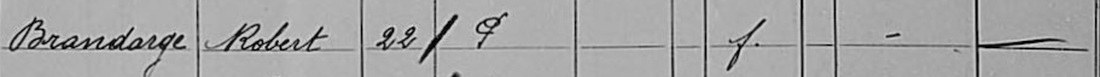

In [14]:
ocr_errors = ocr_cells.loc[
    ocr_cells.available & ocr_cells.filled & ocr_cells.correct.eq(0)
    & ocr_cells.field.isin(["surname", "given_names", "occupation"])]
error_id = ocr_errors.iloc[0].row_id
error_row = ocr_labels.set_index("row_id").loc[error_id]
error_image = PILImage.open(
    ocr_dir / "pages" / f"{error_row.page_id}.png")
x, y, w, h = (int(error_row[k]) for k in ["x", "y", "width", "height"])
display(error_image.crop((x, y, x + w, y + h)).resize(
    (1100, round(h * 1100 / w)), PILImage.Resampling.LANCZOS))
error_table = ocr_cells.loc[
    ocr_cells.row_id.eq(error_id) & ocr_cells.field.isin(fields_shown),
    ["field", "reference", "prediction"],
]
display(HTML(error_table.to_html(index=False)))

- A plausible surname can still break record linkage; a plausible occupation can change an economic classification
- The reference is the published transcription, not agreement between two models. Ambiguous source labels need a separate human audit

## Blank Cells Can Make Accuracy Look Good

In [15]:
by_content = ocr_cells.groupby("filled").agg(
    labeled=("correct", "size"), available=("correct", "count"),
    exact_agreement=("correct", "mean"))
by_content.index = ["Blank reference", "Filled reference"]
print(by_content)

                  labeled  available  exact_agreement
Blank reference       394        380         0.928947
Filled reference      806        805         0.460870

- The education column is blank in all 120 annotation rows. Returning nothing there is easy; it tells us nothing about reading an occupation
- Do not treat extracted variables as error-free data. Errors depend on the writer, field, scan, and abbreviations; they can change which people link across censuses
- For a larger corpus, label new pages from each period and handwriting style, inspect failures, and keep an untouched evaluation sample

## Run the Paris Comparison

Start the MLX server as in the [setup commands](data/README.md), then:

``` bash
mkdir -p build/handwriting/chandra
export OCR_MODEL=build/handwriting/model
uv run --extra handwriting \
  python utilities/build_handwriting_predictions.py \
  --split test --mode pages --output build/handwriting/chandra
uv run --extra handwriting \
  python utilities/build_handwriting_predictions.py \
  --split test --mode rows --output build/handwriting/chandra
uv run --extra handwriting \
  python utilities/build_handwriting_scores.py \
  build/handwriting/chandra --output build/handwriting/scores
```

- Images, labels, and saved responses ship with the [notebooks repository](https://github.com/jlperla/grad_econ_datascience_notebooks). These commands save new results in `build/`
- [Dataset attribution](data/handwriting/ATTRIBUTION.txt), [source metadata](data/handwriting/source.json), and [scoring script](../utilities/build_handwriting_scores.py)

# Fine-Tuning for a Corpus

## What Did the Census Author Train On?

The thesis reports this split for its **final blur-trained model**:

| Role | Pages | Purpose |
|:-----------------------|-----------------------:|:-----------------------|
| Training | 110 | Learn the adapter; includes 33 pages from 1855 |
| Development (“evaluation”) | 14 | Select the model; includes 3 pages from 1855 |
| Final test | 14 | Excluded from training and tuning |

- The original adapter’s full membership is less clearly documented. **We train neither one**
- We show one training page and the author’s **best final-test page**
- Complete final-test image–label pairs are unavailable; this is not the full benchmark. [Thesis, §5.4 and §6](https://odr.chalmers.se/bitstreams/56e9e0b8-2859-4a1c-8d3c-735b0441de16/download#page=62)

## Vibe-coding Warning!

This material has not yet been fully vetted and checked.

## A Census Fine-Tune: Argentina, 1895

<figure>
<img src="https://raw.githubusercontent.com/Saucy-Stream/Argentina_1895_census_HTR_code/1048ba9c12863283ad17b6cde11684e0ed42885d/test/Cordoba_Calamuchita_Ca%C3%B1ada%20de%20%C3%81lvarez_image%2010%20of%20168.jpg" alt="1895 census, Cañada de Álvarez, Córdoba: names, occupations, literacy, and property." />
<figcaption aria-hidden="true">1895 census, Cañada de Álvarez, Córdoba: names, occupations, literacy, and property.</figcaption>
</figure>

- **Spanish, in Roman script.** Image 10 of 168, from the author’s **training set**
- FamilySearch scan via [Ledin (2026)](https://odr.chalmers.se/items/8ba120cd-6603-4f65-aa77-773917e5fba2): [source image directory](https://github.com/Saucy-Stream/Argentina_1895_census_HTR_code/tree/1048ba9c12863283ad17b6cde11684e0ed42885d/test). Downloaded on demand

## A Small Adapter, a Specific Table

- [`Saucystream/fine_tuned_chandra`](https://huggingface.co/Saucystream/fine_tuned_chandra) adapts the **original Chandra**, an 8B model. The Paris example above uses Chandra OCR 2
- **LoRA** learns small matrix updates while holding the base weights fixed. This adapter uses rank 8 and alpha 16 on the language model’s query, key, and value attention projections
- The author’s training pairs whole census pages with **JSON tables**. `A` holds surname and given names, `C` age, `H` occupation, `I` literacy, and `K` property ownership
- Blank cells are `"*"`; split columns become lists. These conventions are part of the task the adapter learns
- The author’s code trains against a 4-bit base. We merge the published adapter into BF16 weights and run locally with MLX, without training. A training-page comparison does not measure performance on unseen pages

## Download the Base Model and Its Adapter

These calls fetch **existing** parameters from Hugging Face:

``` python
import torch
from peft import PeftModel
from transformers import AutoModelForImageTextToText

base = AutoModelForImageTextToText.from_pretrained(
    "datalab-to/chandra",
    revision="bd40c21576564d31ba99f204e28ccd5c4c1751fa",
    dtype=torch.bfloat16, device_map="cpu",
)
adapted = PeftModel.from_pretrained(
    base, "Saucystream/fine_tuned_chandra",
    revision="d94b4ca422dd87e06b55abdd955bb199879a545a",
)
merged = adapted.merge_and_unload()
```

- `merge_and_unload()` adds the learned updates to the base weights. **No optimizer or training step occurs**
- [`build_handwriting_argentina_model.py`](../utilities/build_handwriting_argentina_model.py) also saves the weights, processor, and MLX configuration to `build/handwriting/argentina-model`. [PEFT merging docs](https://huggingface.co/docs/peft/en/developer_guides/model_merging)

## From the Census Image to JSON

In [16]:
import json

argentina_dir = ocr_dir / "argentina"
argentina = json.loads((argentina_dir / "prediction.json").read_text())
first_person = argentina["data"][0]
print(json.dumps({k: first_person[k] for k in ["A", "C", "H", "I", "K"]},
                 ensure_ascii=False, indent=2))

{
  "A": [
    "Zarazaga",
    "José"
  ],
  "C": 45,
  "H": "Comerciante",
  "I": "si",
  "K": "si"
}

- Selected fields for the first person, from a response containing **15 people**. `Comerciante` means merchant
- The model generates this JSON directly. We keep the complete response and leave blanks (`"*"`) and ditto marks uninterpreted

## From Census JSON to pandas

In [17]:
people = pd.DataFrame(argentina["data"])
names = pd.DataFrame(people["A"].tolist(), columns=["surname", "given_names"])
people = pd.concat([names, people[["B", "C", "H", "I", "K"]]], axis=1)
people = people.rename(columns={
    "B": "sex", "C": "age", "H": "occupation",
    "I": "literacy", "K": "property_owner",
})

In [18]:
display(HTML(people[["surname", "given_names", "age", "occupation"]]
             .head(3).to_html(index=False)))

- These are **model predictions**, with no reference labels in the prompt. Blank cells (`"*"`) and ditto marks remain uninterpreted; valid JSON does not verify a name

## Does Newer Chandra Beat the Fine-Tune?

In [19]:
comparison = pd.read_csv(argentina_dir / "scores/summary.csv").set_index("model")
workflows = ["Chandra 1 / HTML", "Chandra 1 + LoRA / JSON",
             "Chandra OCR 2 / HTML"]
result = comparison.loc[workflows]
rate_table = pd.DataFrame({
    "Model / output": workflows,
    "Character accuracy": result.character_accuracy.map("{:.1%}".format),
    "Age digit accuracy": result.digit_accuracy.map("{:.1%}".format),
    "Exact-cell errors": [f"{r.errors:.0f}/{r.available_cells:.0f}"
                          for r in result.itertuples()],
})
display(HTML(rate_table.to_html(index=False)))

- **All three recover 90/90 selected cells automatically.** Character and digit scores give credit for partially correct strings; exact-cell errors remain visible
- The fine-tune has the fewest disagreements. Its character score concerns the **67 filled cells**; blanks have a separate exact score
- This compares **workflows**: both base models use Chandra’s HTML prompt; the adapter uses its author’s JSON prompt. All receive the same image, with BF16 weights and greedy decoding
- **One page from the adapter’s training set.** These percentages describe agreement with its author’s transcription, not accuracy on new census pages

## What Do the Errors Measure?

| HTML workflow    | Periods only | `no` vs `nó` | Ditto `"` vs `''` |
|:-----------------|-------------:|-------------:|------------------:|
| Original Chandra |           24 |            6 |                 0 |
| Chandra OCR 2    |           22 |            6 |                 3 |

- **90 cells = 15 people × 6 fields**: full name, sex, age, occupation, literacy, and property. Character accuracy uses the 67 filled cells
- The table counts **subsets of strict errors**; the adapter has none of these. Much of its advantage concerns transcription conventions
- Both base models write **`4.5`** where the reference gives **`45`**. Punctuation can also change an economic variable
- One uncertain label reads `Jomalero`, versus the adapter’s `Jornalero` (day laborer). Omitting it gives **2/89 = 2.2%** exact disagreements

## The Same JSON Prompt Tests the Interface Too

| Model, with the author’s JSON prompt | Result | Cell errors |
|:---|:---|:---|
| Original Chandra | 15 people; names not split | 51/90 = 56.7% |
| Chandra 1 + Argentina LoRA | 15 people; names split | 3/90 = 3.3% |
| Chandra OCR 2 | Repetition; 0/90 usable cells | Undefined |

- Identical image and instructions do not make an unfamiliar output format equally easy for every model
- The adapter has seen **this page and this prompt** in training. Its result combines handwriting recognition, learned conventions, and possible memorization
- The 8192-token limit yields no complete record for OCR 2: **0% coverage**, undefined reading accuracy, and **0% exact recovery**. The HTML comparison uses its supported interface
- [Saved responses and protocol](data/handwriting/argentina/comparison_protocol.json), [reference source and scoring setup](data/README.md), and [runnable scorer](../utilities/build_handwriting_argentina_scores.py)

## A Page Held Out by the Author

![](https://raw.githubusercontent.com/Saucy-Stream/Argentina_1895_census_HTR_code/1048ba9c12863283ad17b6cde11684e0ed42885d/test/S3HT-62RW-C1Y.jpg_3_7_8.png)

- @ledin2026census sets aside **14 pages for the blur model**, excluded from training and tuning. This was its **best test page**, not a random sample
- We use the **median-blurred** [Figure 5.16](https://odr.chalmers.se/bitstreams/56e9e0b8-2859-4a1c-8d3c-735b0441de16/download#page=64), scored against reference **A.31**. The image displayed here is a thresholded copy

## Run the Census Fine-Tune

- Download/merge the adapter and download the selected held-out image:

``` bash
uv run --extra handwriting \
  python utilities/build_handwriting_argentina_model.py
uv run python utilities/build_handwriting_argentina_holdout.py
```

- Run the small Python caller directly, without a server:

``` bash
uv run --extra handwriting --extra handwriting-mac \
  python code/handwriting_mlx.py \
  build/handwriting/argentina/holdout/source-000.png \
  --model build/handwriting/argentina-model --max-tokens 8192 \
  --prompt-source \
  slides/data/handwriting/argentina/holdout/finetuned-json/source.json
```

- Base weights and the merged copy each need about **17 GB**. The image extractor needs Poppler; source files stay in `build/`
- [Server-based benchmark commands](data/README.md) also save responses and run metadata; the small caller above prints raw JSON

## Call the Adapted Model on an Image Path

[`handwriting_mlx.py`](../code/handwriting_mlx.py) loads the merged weights **inside Python**, without a server:

``` python
import json
from pathlib import Path
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.utils import load_config

model_path = "build/handwriting/argentina-model"
image_path = "build/handwriting/argentina/holdout/source-000.png"
data = Path("slides/data/handwriting/argentina/holdout")
source = json.loads((data / "finetuned-json/source.json").read_text())
messages = [
    {"role": "system", "content": source["system_prompt"]},
    {"role": "user", "content": source["user_prompt"]},
]
model, processor = load(model_path)
prompt = apply_chat_template(
    processor, load_config(model_path), messages, num_images=1,
)
result = generate(model, processor, prompt, image=[image_path],
                  max_tokens=8192, temperature=0.0, verbose=False)
print(result.text)
```

- `source.json` supplies the author’s full **JSON instructions** and made-up schema example; it supplies no answers for this page
- Use this prompt with the fine-tuned model; use `OCR_PROMPT` for the base-model HTML runs

## Holdout: Does the Advantage Survive?

In [20]:
holdout = pd.read_csv(argentina_dir / "holdout/scores/summary.csv")
holdout_labels = ["Chandra 1 / HTML", "Chandra 1 + LoRA / JSON",
                  "Chandra OCR 2 / HTML"]
holdout = holdout.set_index("model").loc[holdout_labels]
holdout_table = pd.DataFrame({
    "Model / output": ["Chandra 1 / HTML", "Original LoRA / JSON",
                       "Chandra OCR 2 / HTML"],
    "Character accuracy": holdout.character_accuracy.map(
        "{:.1%}".format).to_numpy(),
    "Age digit accuracy": holdout.digit_accuracy.map(
        "{:.1%}".format).to_numpy(),
    "Exact-cell errors": [
        f"{r.errors:.0f}/{r.available_cells:.0f} = {r.error_rate:.1%}"
        for r in holdout.itertuples()],
})
display(HTML(holdout_table.to_html(index=False)))

- Same **15 people × 6 fields**, common image, BF16 weights, and greedy decoding. Each model uses its native output prompt
- **Source-audited results:** all 90 cells are available, but OCR 2 requires a structural repair for **54 cells**. These reading scores do not establish that it can recover the layout unaided
- The **blur LoRA** also gives **11/90**. Input blur matches its training, and the author selected its best page; the original adapter was trained without blur. This is not a representative comparison

## Credit the Model That Gets the Layout Right

In [21]:
layout_table = pd.DataFrame({
    "Model": holdout_table["Model / output"],
    "Automatic cells": [f"{r.automatic_cells:.0f}/90"
                        for r in holdout.itertuples()],
    "Assisted cells": holdout.assisted_cells.to_numpy(),
    "Automatic exact recovery": holdout.automatic_exact_yield.map(
        "{:.1%}".format).to_numpy(),
})
display(HTML(layout_table.to_html(index=False)))

- The reader aligns **15/15 rows** for original Chandra and the fine-tune, versus **6/15** for OCR 2. Its colspan rule was added **after viewing Chandra 1’s output**
- The fine-tune has the strongest automatic exact recovery on this page
- Availability is not correctness: original Chandra still places some values in the wrong columns, including the two filled property cells. Those remain disagreements
- Keep both measures: **automatic recovery** for a usable pipeline, and **reading accuracy after documented alignment** to diagnose the handwriting model

## When the Table Breaks

In [22]:
from bs4 import BeautifulSoup

html_path = argentina_dir / "holdout/chandra2-html/prediction.html"
html_rows = BeautifulSoup(html_path.read_text(), "html.parser")
entries = [[td.get_text(strip=True) for td in tr.find_all("td")]
           for tr in html_rows.find_all("tr") if tr.find_all("td")]
broken_rows = pd.DataFrame([entries[5][:6], entries[6][:6]], columns=[
    "Row no.", "Name 1", "Name 2", "Sex", "Age", "Marital status",
])
display(HTML(broken_rows.to_html(index=False)))

- Actual OCR 2 output: the sixth row fits the printed columns. The seventh starts with **`P.1`**, a margin note, pushing the row number and name one column right
- OCR 2 also drops the province column. The right side then lines up by coincidence; a uniform shift would put other variables in the wrong columns
- The HTML parses, yet its body contradicts its header. **Valid output syntax does not guarantee a usable DataFrame**
- A source-checked map shifts only the left-page fields and recovers the other nine rows. It changes **no predicted text**; the [hash-bound audit](data/handwriting/layout_audit.json) records this retrospective assistance

## Holdout Labels Also Need an Audit

In [23]:
sensitivity = pd.DataFrame({
    "Model": holdout_table["Model / output"],
    "Exact errors / 90": holdout.errors.to_numpy(),
    "Omit 5 uncertain cells / 85": holdout.unflagged_errors.to_numpy(),
})
display(HTML(sensitivity.to_html(index=False)))

- A visual review flagged **four names and one occupation** before we inspected model predictions. We retain the published labels; excluding these cells changes the denominator to 85
- After the source audit, **15** disagreements for each base model concern only a period (`V.` versus `V`). Neither adapter has these discrepancies; digit and character scores retain punctuation
- Reference agreement measures reading, coding conventions, and table extraction together. Ignoring accents alone leaves all these scores unchanged
- [Saved responses and protocol](data/handwriting/argentina/holdout/comparison_protocol.json), [holdout search](data/handwriting/argentina/holdout/search_sources.json), and [download and scoring commands](data/README.md)

# Thai Bills

## Vibe-coding Warning!

This material has not yet been fully vetted and checked.

## A Thai Bill Fine-Tune

<figure>
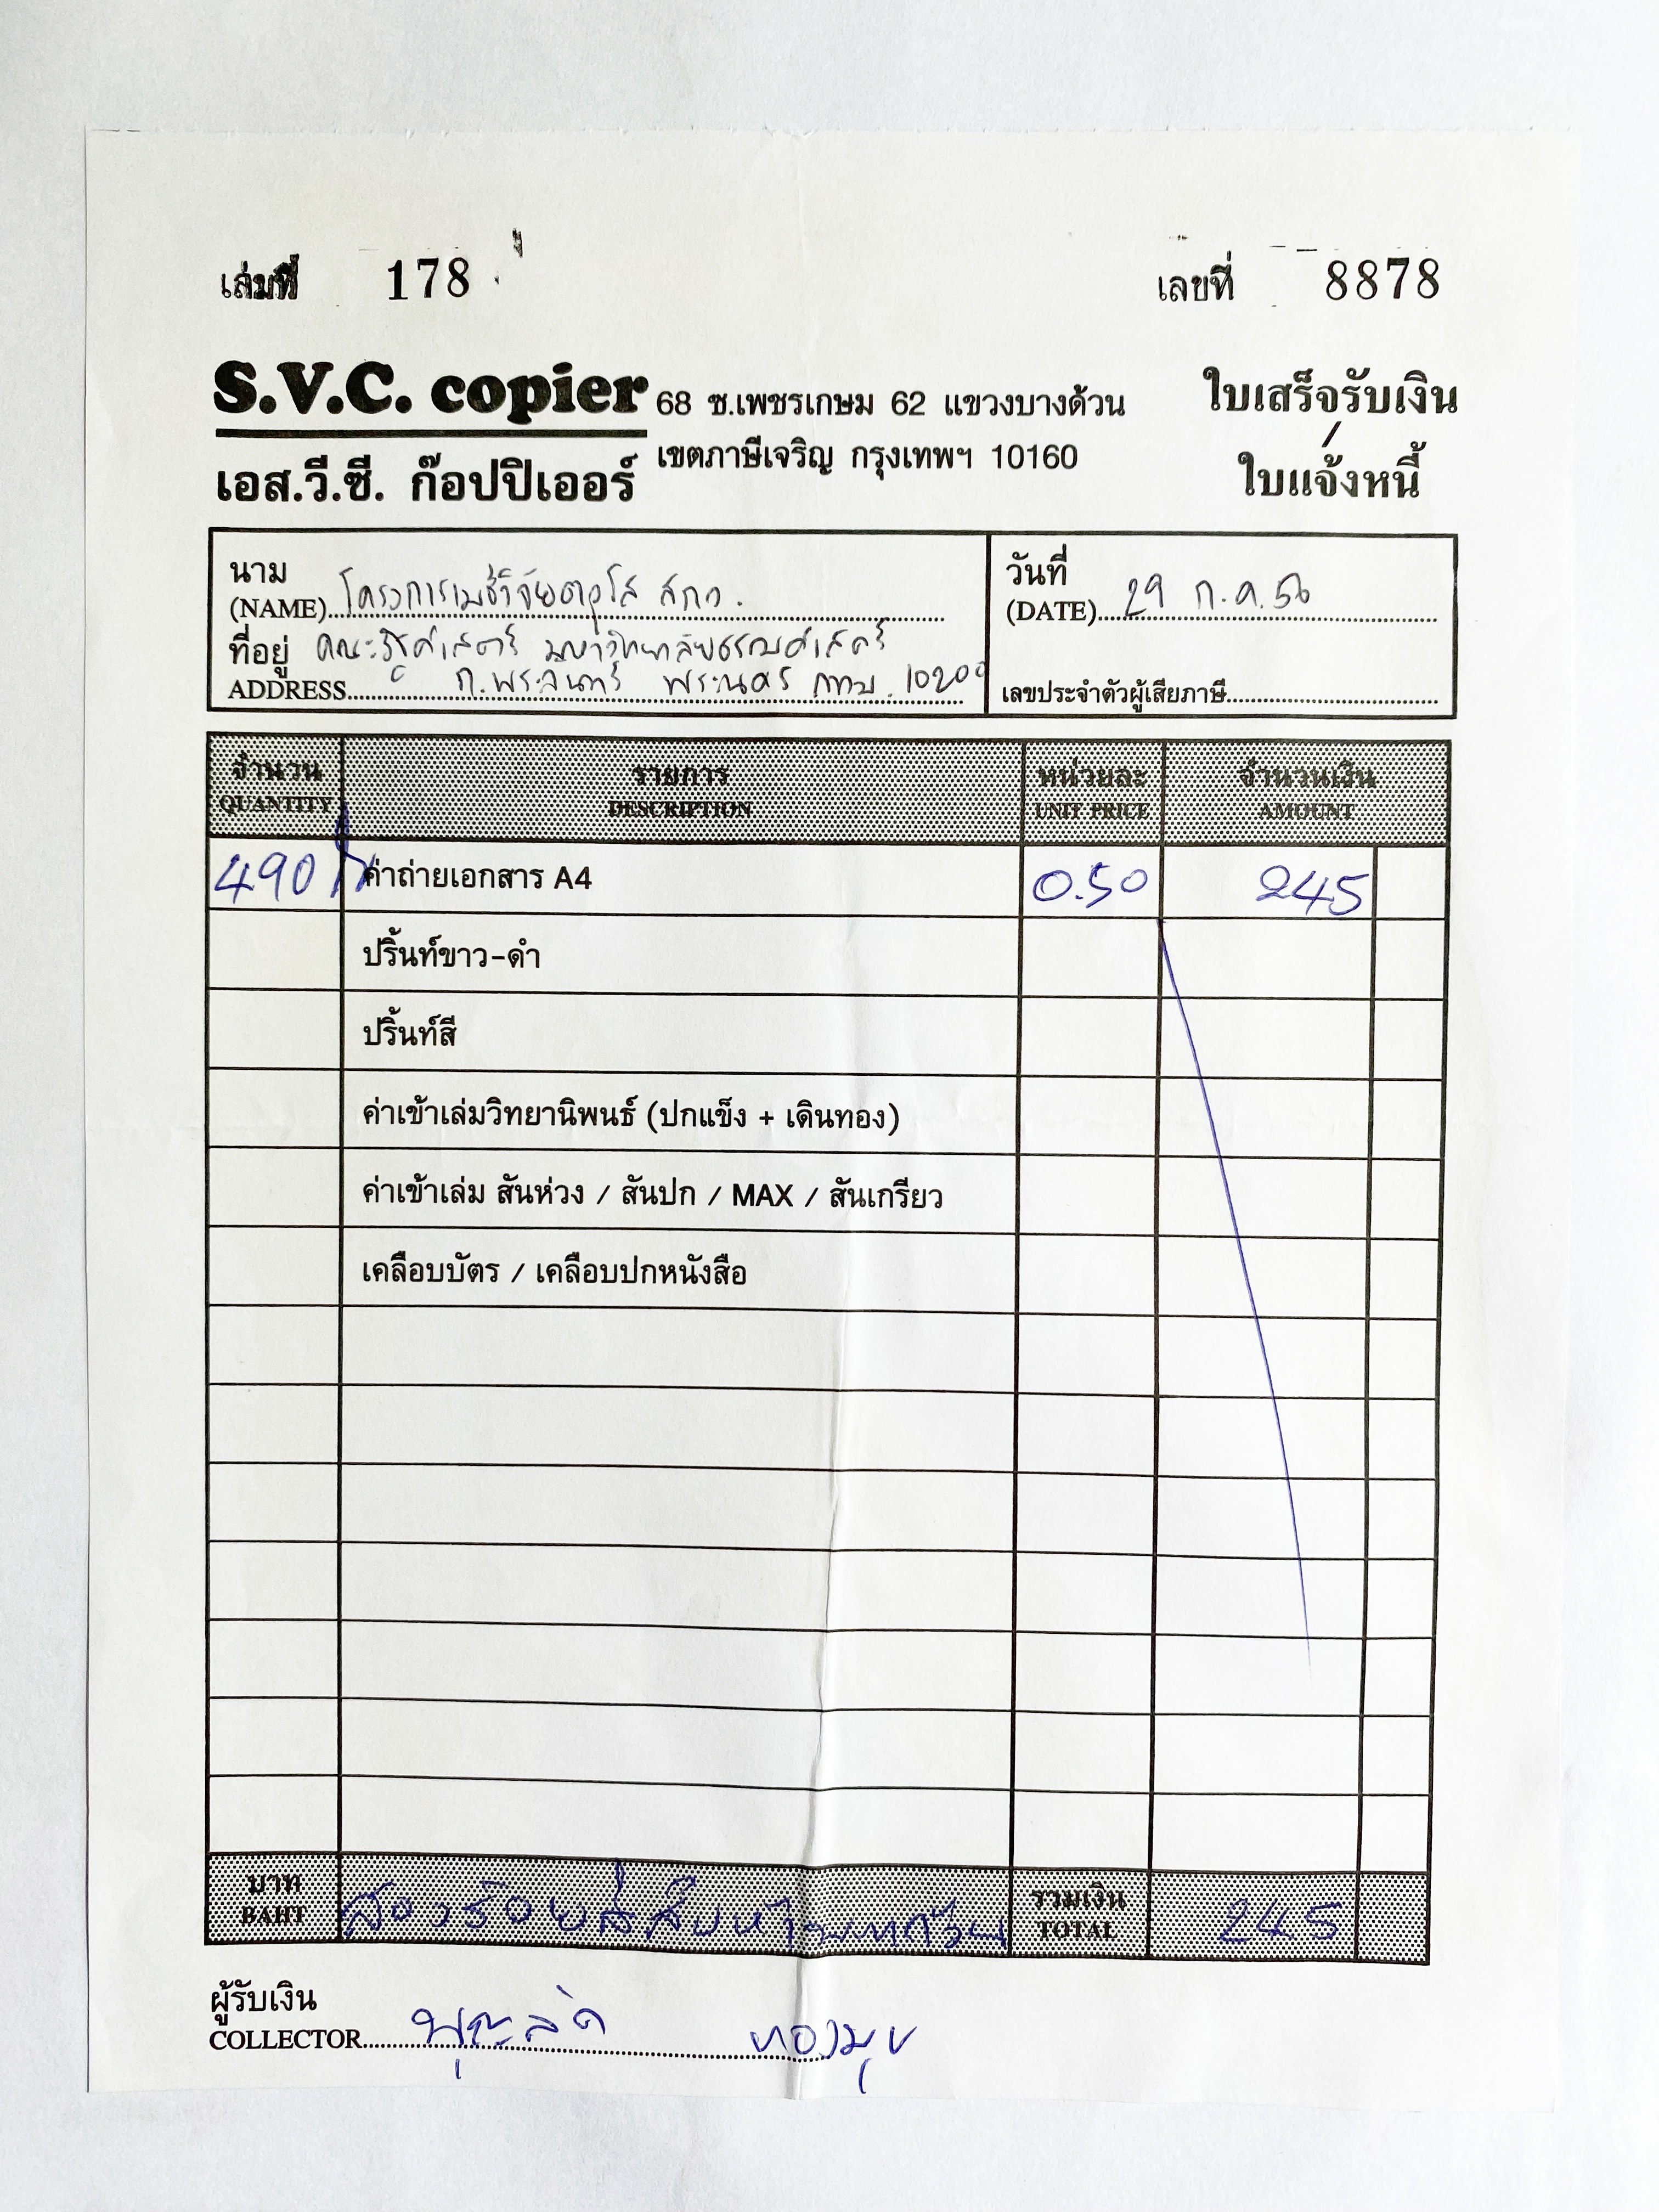
<figcaption aria-hidden="true">Appen bill with handwritten quantities and prices.</figcaption>
</figure>

- [`ChandraOCR2_AppenDoc`](https://huggingface.co/fwgpiyawudk/ChandraOCR2_AppenDoc-merged) merges a fine-tune into Chandra OCR 2
- **LoRA** learns small matrix updates. The author’s [configuration](https://huggingface.co/fwgpiyawudk/ChandraOCR2_AppenDoc-LoRA/blob/main/adapter_config.json) uses rank 32 and scaling parameter 64
- The author’s [dataset](https://huggingface.co/datasets/fwgpiyawudk/appen-thai-doc) includes this Appen bill with printed headings and handwritten entries
- We run **one cropped item row** locally. Both images are included (Appen Limited, CC BY-SA 4.0)
- The image is from the dataset’s **train split**; exact adapter training membership is undocumented. We have **no held-out evaluation** for this example

## A Merged Fine-Tune Loads Like the Base Model

Download the Thai checkpoint, which already includes its adapter:

``` python
from huggingface_hub import snapshot_download

model_path = snapshot_download(
    "fwgpiyawudk/ChandraOCR2_AppenDoc-merged",
    revision="dde20ac03d4dbc851af082576c7b34f095cf12e0",
    local_dir="build/handwriting/appen-model",
)
```

Reuse the Chandra Python call, changing the model and image paths:

``` python
image_path = "slides/data/handwriting/appen/input.png"
model, processor = load(model_path)
prompt = apply_chat_template(
    processor, load_config(model_path), OCR_PROMPT, num_images=1,
)
result = generate(model, processor, prompt, image=[image_path],
                  max_tokens=2048, temperature=0.0, verbose=False)
print(result.text)
```

- It returns **HTML**. Unlike the Argentine adapter, this model uses Chandra’s OCR prompt
- The same [`handwriting_mlx.py`](../code/handwriting_mlx.py) accepts `--model build/handwriting/appen-model`; no separate adapter merge is needed

## From a Handwritten Bill to JSON

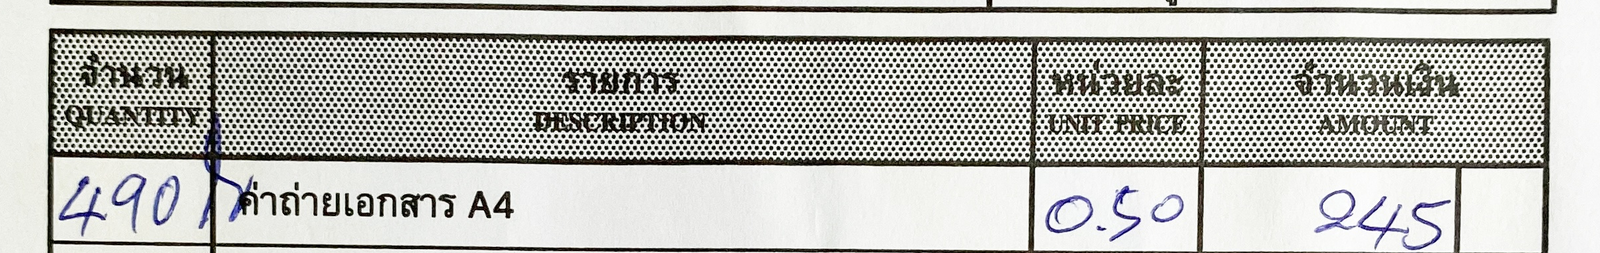

In [24]:
import json

appen_dir = ocr_dir / "appen"
item = json.loads((appen_dir / "prediction.json").read_text())[0]
print(json.dumps(item, ensure_ascii=False, indent=2))

{
  "quantity": "490",
  "description": "ค่าถ่ายเอกสาร A4",
  "unit_price": "0.50",
  "amount": "245"
}

- The model’s HTML table becomes JSON through `pd.read_html`. The Thai description denotes A4 photocopying; $490 \times 0.50 = 245$
- Full-page extraction repeated empty rows. This demonstrates the visible crop; locating it is a separate step
- [Pinned setup](data/README.md) and [runnable extraction script](../utilities/build_handwriting_finetune.py)

# Fine Tuning Yourself

## From Labeled Pages to a LoRA Adapter

1.  **Split writers/documents:** training, development, and untouched test pages
2.  **Pair scans with verified answers:** consistent HTML or JSON targets, using the model’s image processor and chat template
3.  **Train LoRA updates:** freeze base weights; supervise the answer tokens and end token
4.  **Choose settings on development pages:** learning rate, epochs, rank, and image size. Inspect generated tables
5.  **Compare on test pages:** base versus adapter, with coverage and character/digit errors. Save the adapter, base revision, and processor

- Guides: [PEFT / LoRA](https://huggingface.co/docs/peft/en/developer_guides/lora), [TRL vision-language training](https://huggingface.co/docs/trl/en/sft_trainer#training-vision-language-models), and the [census author’s code](https://github.com/Saucy-Stream/Argentina_1895_census_HTR_code). **Recipe sketch; no training run here**

## References

- [York CCRI: Toronto Area Test Sample and data-entry manual](https://www.yorku.ca/ccri/)
- [Library and Archives Canada: 1901 census](https://www.canada.ca/en/library-archives/collection/research-help/genealogy-family-history/censuses/dominion-canada/1901.html)
- [Constum et al. (2022): POPP data and citation](https://doi.org/10.5281/zenodo.6581158)
- [Datalab: Chandra OCR 2](https://huggingface.co/datalab-to/chandra-ocr-2)
- [MLX-VLM: local inference on Apple Silicon](https://github.com/Blaizzy/mlx-vlm)
- [Appen Thai fine-tune](https://huggingface.co/fwgpiyawudk/ChandraOCR2_AppenDoc-merged) and [source images](https://www.kaggle.com/datasets/appenlimited/ocr-image-data-for-thai-documents)
- [Argentine census adapter](https://huggingface.co/Saucystream/fine_tuned_chandra) and [author’s source pages and code](https://github.com/Saucy-Stream/Argentina_1895_census_HTR_code)